# TP3 - Procesamiento del Lenguaje Natural (NLP)
**Inteligencia Artificial y Neurociencias**

**Leoni, Petra - Mendez, Agustín - Pizi, Lucía - Siles, Milagros**

## 3. Modelos preentrenados

En esta parte evaluamos un encoder preentrenado en español, **BETO** (`dccuchile/bert-base-spanish-wwm-cased`), de dos formas:

1. **Sin fine-tuning:** el encoder queda congelado y se usa solo como extractor de *embeddings*. Sobre esos vectores se entrena una Regresión Logística balanceada (el mismo clasificador que en la parte 2), así que la diferencia con la parte 2 es únicamente la representación del texto.

2. **Con fine-tuning:** se ajustan todos los pesos del encoder junto con una capa de clasificación. Se exploran tres decisiones de entrenamiento: *learning rate*, cantidad de épocas y longitud máxima de secuencia.

Para evaluar:
- Usamos exactamente los conjuntos de `splits_tp3.csv` (split agrupado por propuesta, ≈70/15/15).

- Todas las decisiones se toman con validación. El conjunto de test se usa una única vez, al final.
- Como métrica principal usamos **Macro-F1** respecto de `majority_label`. Se reportan además *accuracy*, F1 por clase, tiempos de entrenamiento e inferencia y uso de VRAM.

### 3.0. Configuración

In [1]:
!pip -q install datasets

In [2]:
import os
import gc
import time
import random
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

import torch
from torch.utils.data import DataLoader
import transformers
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
CLASES = ["favor", "against", "neutral"]   # mismo orden que en las partes 1 y 2
label2id = {c: i for i, c in enumerate(CLASES)}
id2label = {i: c for c, i in label2id.items()}
MODELO = "dccuchile/bert-base-spanish-wwm-cased"   # BETO (cased)

sns.set_theme(style="whitegrid")
transformers.logging.set_verbosity_error()   # oculta el aviso de "pesos nuevos" de la cabeza de clasificación

def fijar_semilla(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

fijar_semilla(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USA_AMP = DEVICE.type == "cuda"   # precisión mixta (fp16) solo en GPU

def sincronizar():
    """Espera a que termine el trabajo en la GPU (necesario para medir tiempos correctamente)."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

# Hardware / versiones (para reportar costos)
print("Python:", platform.python_version(), "| torch:", torch.__version__,
      "| transformers:", transformers.__version__, "| scikit-learn:", sklearn.__version__)
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())
if DEVICE.type == "cuda":
    prop = torch.cuda.get_device_properties(0)
    print(f"GPU: {prop.name} | VRAM total: {prop.total_memory / 1e9:.1f} GB")
else:
    print("ATENCIÓN: no hay GPU disponible. El fine-tuning en CPU es muy lento; "
          "activar la GPU en Colab antes de seguir.")

Python: 3.13.16 | torch: 2.14.1+cu130 | transformers: 5.22.1 | scikit-learn: 1.6.1
CPU: x86_64 | núcleos: 2
GPU: Tesla T4 | VRAM total: 15.6 GB


### 3.1. Carga de datos y particiones

Se reconstruye `df_modelado` igual que en las partes 1 y 2 (se descartan los 150 comentarios sin mayoría) y se asigna a cada comentario su conjunto según `splits_tp3.csv`.

In [3]:
dataset = load_dataset("SINAI/ALIA-es-discriminative-stance-detection")
df = dataset["train"].to_pandas()

cols_anotadores = ["annotation_1", "annotation_2", "annotation_3"]
df_modelado = df[df["majority_label"].isin(CLASES)].copy().reset_index(drop=True)
df_modelado["label"] = df_modelado["majority_label"]
df_modelado["label_id"] = df_modelado["label"].map(label2id)
df_modelado["id"] = df_modelado["id"].astype(str)

# Nivel de acuerdo entre anotadores (se usa en el análisis de errores)
df_modelado["max_acuerdo"] = df_modelado[cols_anotadores].apply(lambda f: f.value_counts().max(), axis=1)
df_modelado["nivel_acuerdo"] = df_modelado["max_acuerdo"].map({3: "Total (3/3)", 2: "Parcial (2/3)"})

RUTA_SPLITS = "splits_tp3.csv"
if not os.path.exists(RUTA_SPLITS):
    try:
        from google.colab import files
        print("No se encontró splits_tp3.csv: subilo (lo genera la parte 1).")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Falta splits_tp3.csv (lo genera la parte 1).")

splits = pd.read_csv(RUTA_SPLITS, dtype={"id": str})
df_modelado = df_modelado.merge(splits, on="id", how="left", validate="one_to_one")
assert df_modelado["split"].notna().all(), "Hay comentarios sin split asignado"

train_df = df_modelado[df_modelado["split"] == "train"].reset_index(drop=True)
val_df = df_modelado[df_modelado["split"] == "val"].reset_index(drop=True)
test_df = df_modelado[df_modelado["split"] == "test"].reset_index(drop=True)
DFS = {"train": train_df, "val": val_df, "test": test_df}

# Controles: todos los comentarios tienen split y no hay propuestas compartidas
assert len(train_df) + len(val_df) + len(test_df) == len(df_modelado) == 2850
print(f"Train: {len(train_df)} | Validación: {len(val_df)} | Test: {len(test_df)}")
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not set(a["target"]) & set(b["target"])

y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

display(pd.crosstab(df_modelado["split"], df_modelado["label"]).loc[["train", "val", "test"], CLASES])

README.md:   0%|          | 0.00/20.1k [00:00<?, ?B/s]

corpus_stance_detection_ALIA.jsonl:   0%|          | 0.00/4.48M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3000 [00:00<?, ? examples/s]

No se encontró splits_tp3.csv: subilo (lo genera la parte 1).


Saving splits_tp3.csv to splits_tp3.csv
Train: 2019 | Validación: 413 | Test: 418


label,favor,against,neutral
split,,,
train,1262,445,312
val,261,87,65
test,257,95,66


### 3.2. Tokenización y entrada del modelo

BETO trae su propio tokenizador (WordPiece, vocabulario de 31.000 subpalabras, distingue mayúsculas). A diferencia de la parte 2, no se aplica preprocesamiento, ya que el modelo fue preentrenado sobre texto natural, así que mayúsculas, acentos, stopwords y signos de puntuación se conservan (las negaciones y las mayúsculas sostenidas, como *"NO SE PUEDE"*, pueden llevar información de postura).

La postura se define respecto de una propuesta (en la parte 1 vimos que el mismo texto puede ser *favor* en una propuesta y *against* en otra). Un encoder tipo BERT puede recibir dos segmentos separados por `[SEP]` y modelar la relación entre ambos con la atención, algo que la bolsa de palabras de la parte 2 no podía hacer. Por eso se usa como entrada el par *(título de la propuesta, comentario)*:

`[CLS] título de la propuesta [SEP] comentario [SEP]`

No se agrega la `description` porque es muy larga (mediana de 105 palabras, máximo 944) y con ella se superarían fácilmente los 512 tokens. En la evaluación sin fine-tuning, que es barata, se compara además contra usar solo el comentario.

Se mide la longitud en tokens para elegir las longitudes máximas a probar.

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

,comentario,propuesta + comentario
count,2850.0,2850.0
mean,71.1,82.7
std,41.1,41.5
min,15.0,19.0
50%,61.0,72.0
75%,98.0,111.0
90%,133.0,145.0
95%,151.0,164.0
99%,178.0,190.5
max,241.0,250.0


,% truncado con max_len=64,% truncado con max_len=128,% truncado con max_len=256
comentario,46.8,11.5,0.0
propuesta + comentario,57.5,15.9,0.0


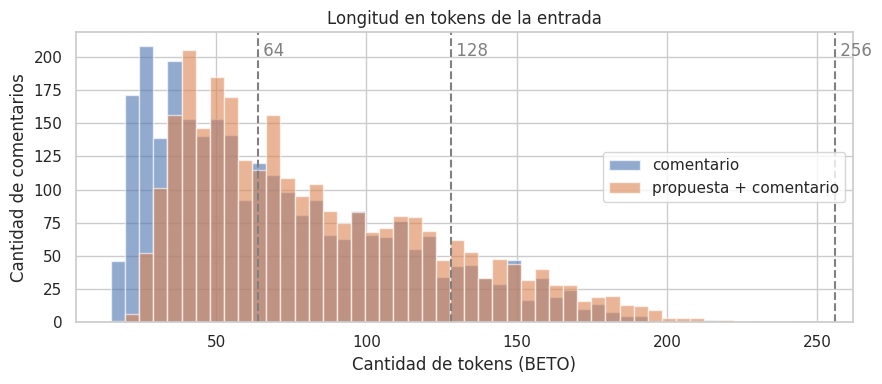

Ejemplo de entrada tokenizada:
[CLS] " Bajar " las motos de las aceras. [SEP] A mi no me molesta tanto que aparquen en la acera. Me molesta mucho más que circulen por ella. Respecto a lo de prohibir la circulación por las aceras, no es necesario prohibirlo, por que ya está prohibido. Lo que hace falta es que se multe a las motos que lo hagan [SEP]


In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODELO)

largo_com = [len(x) for x in tokenizer(list(df_modelado["comment"]))["input_ids"]]
largo_par = [len(x) for x in tokenizer(list(df_modelado["target"]), list(df_modelado["comment"]))["input_ids"]]
largos = pd.DataFrame({"comentario": largo_com, "propuesta + comentario": largo_par})
display(largos.describe(percentiles=[.5, .75, .9, .95, .99]).round(1))

LONGITUDES = [64, 128, 256]
display(pd.DataFrame({L: (largos > L).mean() * 100 for L in LONGITUDES}).round(1)
        .rename(columns=lambda L: f"% truncado con max_len={L}"))

ax = largos.plot.hist(bins=50, alpha=0.6, figsize=(9, 4))
for L in LONGITUDES:
    ax.axvline(L, ls="--", c="gray")
    ax.text(L, ax.get_ylim()[1] * 0.92, f" {L}", color="gray")
ax.set_xlabel("Cantidad de tokens (BETO)"); ax.set_ylabel("Cantidad de comentarios")
ax.set_title("Longitud en tokens de la entrada"); plt.tight_layout(); plt.show()

print("Ejemplo de entrada tokenizada:")
print(tokenizer.decode(tokenizer(train_df["target"].iloc[0], train_df["comment"].iloc[0])["input_ids"])[:400])

**Observaciones**

- Los comentarios tienen una mediana de 61 tokens (72 con el título de la propuesta) y un máximo de 241 (250 con el título). El tokenizador genera ≈1,3 tokens por palabra.

- Con la entrada *propuesta + comentario*, 64 tokens truncan el 57,5% de las entradas, 128 truncan el 15,9% y 256 no truncan ninguna. Por eso los embeddings sin fine-tuning se extraen con 256, y se compara 64 / 128 / 256.
- El costo de un transformer crece con la longitud de la secuencia (la atención es cuadrática), así que no conviene usar una longitud mayor que la necesaria.

#### Funciones auxiliares

Se definen la tokenización por conjunto (con *padding* dinámico por batch, para no rellenar todo hasta `max_len`), las métricas y el registro de experimentos.

In [5]:
collator = DataCollatorWithPadding(tokenizer)

def tokenizar(df_split, max_len, entrada="par", con_labels=False):
    """Devuelve una lista de ejemplos tokenizados (el padding lo hace el collator por batch)."""
    if entrada == "par":
        enc = tokenizer(list(df_split["target"]), list(df_split["comment"]),
                        truncation="longest_first", max_length=max_len)
    elif entrada == "comentario":
        enc = tokenizer(list(df_split["comment"]), truncation=True, max_length=max_len)
    else:
        raise ValueError(entrada)
    ejemplos = [{k: enc[k][i] for k in enc.keys()} for i in range(len(df_split))]
    if con_labels:
        for ej, y in zip(ejemplos, df_split["label_id"]):
            ej["labels"] = int(y)
    return ejemplos

def a_device(batch):
    return {k: v.to(DEVICE) for k, v in batch.items() if k != "labels"}

def metricas(y_true, y_pred):
    f1s = f1_score(y_true, y_pred, labels=CLASES, average=None, zero_division=0)
    return {"macro_f1": f1_score(y_true, y_pred, labels=CLASES, average="macro", zero_division=0),
            "accuracy": accuracy_score(y_true, y_pred),
            **{f"f1_{c}": f for c, f in zip(CLASES, f1s)}}

COLS_METRICAS = ["macro_f1", "accuracy"] + [f"f1_{c}" for c in CLASES]

def tamaño_modelo_mb(modelo):
    return sum(p.numel() * p.element_size() for p in modelo.parameters()) / 1e6

### 3.3. BETO sin fine-tuning: embeddings congelados + Regresión Logística

El encoder se usa tal como fue preentrenado, sin modificar sus pesos. Para cada comentario se extrae un vector de 768 dimensiones con tres estrategias de *pooling*:

| Pooling | Qué hace |
|---|---|
| `cls` | Vector del token `[CLS]` de la última capa |
| `mean` | Promedio de los vectores de todos los tokens de la última capa (ignorando el padding) |
| `mean_4` | Promedio de los tokens, promediando además las últimas 4 capas |

BETO no fue preentrenado con un objetivo que haga del `[CLS]` un buen resumen de la oración (solo *masked language modeling*), así que es esperable que el promedio de tokens funcione mejor.

Sobre esos vectores se entrena una Regresión Logística con `class_weight="balanced"` (la misma decisión de desbalance que en la parte 2), estandarizando las features y eligiendo `C` en validación. Se comparan las dos entradas (`comentario` y `par`).

Los embeddings se extraen una sola vez para todos los conjuntos (incluido test) y la extracción no usa etiquetas, así que no filtra información.

In [6]:
POOLINGS = ["cls", "mean", "mean_4"]
MAX_LEN_EMB = 256   # cubre prácticamente todas las entradas (ver 3.2)

@torch.no_grad()
def extraer_embeddings(modelo, df_split, entrada, max_len=MAX_LEN_EMB, batch_size=64):
    loader = DataLoader(tokenizar(df_split, max_len, entrada), batch_size=batch_size,
                        shuffle=False, collate_fn=collator)
    salidas = {p: [] for p in POOLINGS}
    for batch in loader:
        batch = a_device(batch)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USA_AMP):
            out = modelo(**batch, output_hidden_states=True)
        mask = batch["attention_mask"].unsqueeze(-1).float()
        ultima = out.last_hidden_state.float()
        ult4 = torch.stack(out.hidden_states[-4:]).float().mean(0)
        salidas["cls"].append(ultima[:, 0].cpu())
        salidas["mean"].append(((ultima * mask).sum(1) / mask.sum(1)).cpu())
        salidas["mean_4"].append(((ult4 * mask).sum(1) / mask.sum(1)).cpu())
    return {p: torch.cat(v).numpy() for p, v in salidas.items()}

encoder = AutoModel.from_pretrained(MODELO).to(DEVICE).eval()
TAMAÑO_BETO_MB = tamaño_modelo_mb(encoder)
print(f"Parámetros del encoder: {sum(p.numel() for p in encoder.parameters()) / 1e6:.0f} M "
      f"({TAMAÑO_BETO_MB:.0f} MB en fp32)")

# Calentamiento (la primera llamada en GPU incluye inicializaciones que no son parte del costo real)
extraer_embeddings(encoder, train_df.head(64), "par")

EMB, T_EMB = {}, {}
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
for entrada in ["comentario", "par"]:
    for split, d in DFS.items():
        sincronizar(); t0 = time.perf_counter()
        EMB[(entrada, split)] = extraer_embeddings(encoder, d, entrada)
        sincronizar(); T_EMB[(entrada, split)] = time.perf_counter() - t0
        print(f"{entrada:10s} | {split:5s}: {len(d)} textos en {T_EMB[(entrada, split)]:.1f} s")
VRAM_EMB_GB = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan
print(f"VRAM pico durante la extracción: {VRAM_EMB_GB:.2f} GB")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Parámetros del encoder: 110 M (439 MB en fp32)
comentario | train: 2019 textos en 6.3 s
comentario | val  : 413 textos en 1.4 s
comentario | test : 418 textos en 1.4 s
par        | train: 2019 textos en 7.2 s
par        | val  : 413 textos en 1.5 s
par        | test : 418 textos en 1.5 s
VRAM pico durante la extracción: 2.05 GB


In [7]:
resultados = []   # registro de todos los experimentos sobre validación

def registrar(grupo, experimento, y_true, y_pred, **extra):
    fila = {"grupo": grupo, "experimento": experimento, **metricas(y_true, y_pred), **extra}
    resultados.append(fila)
    return fila

def clf_embeddings(C):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, max_iter=5000, class_weight="balanced", random_state=SEED))

for entrada in ["comentario", "par"]:
    for pooling in POOLINGS:
        for C in [0.001, 0.01, 0.1, 1.0]:
            clf = clf_embeddings(C)
            t0 = time.perf_counter()
            clf.fit(EMB[(entrada, "train")][pooling], y_train)
            t_fit = time.perf_counter() - t0
            y_pred = clf.predict(EMB[(entrada, "val")][pooling])
            registrar("sin_finetuning", f"{entrada} | {pooling} | C={C}", y_val, y_pred,
                      entrada=entrada, pooling=pooling, C=C, t_fit_logreg_s=t_fit)

sin_ft = pd.DataFrame([r for r in resultados if r["grupo"] == "sin_finetuning"])
display(sin_ft.sort_values("macro_f1", ascending=False)
        .set_index("experimento")[COLS_METRICAS + ["t_fit_logreg_s"]].head(10).round(3))

,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_fit_logreg_s
experimento,,,,,,
par | mean_4 | C=0.001,0.495,0.535,0.624,0.462,0.400,0.413
comentario | cls | C=0.001,0.487,0.528,0.622,0.467,0.371,1.294
comentario | cls | C=0.01,0.485,0.540,0.640,0.485,0.329,2.409
comentario | mean_4 | C=0.001,0.483,0.525,0.616,0.466,0.367,0.367
par | mean_4 | C=0.01,0.477,0.554,0.681,0.448,0.303,0.515
par | cls | C=0.001,0.475,0.552,0.665,0.471,0.288,0.602
par | mean | C=0.001,0.475,0.518,0.617,0.437,0.369,0.360
comentario | mean_4 | C=0.1,0.472,0.562,0.687,0.427,0.302,1.410
comentario | mean | C=0.001,0.469,0.516,0.618,0.459,0.329,0.651


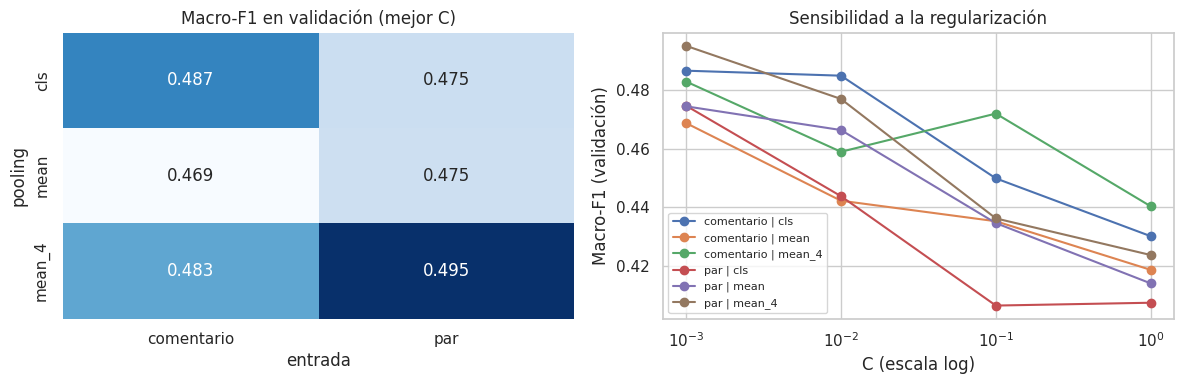

Mejor configuración sin fine-tuning: par | mean_4 | C=0.001 → Macro-F1 (val) = 0.495


In [8]:
# Mejor C para cada combinación de entrada y pooling
mejor_C = sin_ft.loc[sin_ft.groupby(["entrada", "pooling"])["macro_f1"].idxmax()]
piv = mejor_C.pivot(index="pooling", columns="entrada", values="macro_f1").loc[POOLINGS]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Macro-F1 en validación (mejor C)")

for (entrada, pooling), g in sin_ft.groupby(["entrada", "pooling"]):
    axes[1].plot(g["C"], g["macro_f1"], marker="o", label=f"{entrada} | {pooling}")
axes[1].set_xscale("log"); axes[1].set_xlabel("C (escala log)"); axes[1].set_ylabel("Macro-F1 (validación)")
axes[1].set_title("Sensibilidad a la regularización"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

MEJOR_SIN_FT = max((r for r in resultados if r["grupo"] == "sin_finetuning"), key=lambda r: r["macro_f1"])
print("Mejor configuración sin fine-tuning:", MEJOR_SIN_FT["experimento"],
      f"→ Macro-F1 (val) = {MEJOR_SIN_FT['macro_f1']:.3f}")

In [9]:
# Se libera el encoder congelado antes de pasar al fine-tuning
del encoder
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

**Observaciones**

- **Resultado:** la mejor configuración (*par* | `mean_4` | `C=0.001`) obtiene un Macro-F1 de 0,495 en validación, prácticamente igual al mejor modelo clásico de la parte 2 en validación (0,493). Usar embeddings genéricos de BETO en lugar de n-gramas de caracteres, con el mismo clasificador, no aporta una mejora clara.

- **Pooling:** las diferencias son chicas (las 4 mejores combinaciones quedan entre 0,483 y 0,495) y no hay un patrón consistente. Con la entrada *par* gana el promedio de las últimas 4 capas, y con *comentario* el `[CLS]` queda incluso apenas por encima. La hipótesis de que el `[CLS]` sin fine-tuning es una mala representación no se confirma con claridad.
- **Entrada:** agregar el título de la propuesta da la mejor combinación, pero la diferencia con usar solo el comentario (0,487) está dentro del ruido. Con el encoder congelado, el vector del par no está entrenado para representar la *relación* entre ambos segmentos.
- **Regularización:** las mejores configuraciones usan siempre el `C` más chico de la grilla (0,001). Con 768 features densas y ≈2.000 ejemplos, el modelo necesita mucha regularización. *Limitación:* como el óptimo quedó en el borde de la grilla, no se puede descartar que un `C` todavía menor (1e-4) funcione algo mejor.
- **Costo:** extraer los embeddings de los 2.850 comentarios toma ≈10 s por entrada en una T4 (2 GB de VRAM pico) y la regresión logística se ajusta en menos de 1,5 s.

### 3.4. BETO con fine-tuning

Se agrega una capa lineal de clasificación sobre el `[CLS]` (`AutoModelForSequenceClassification`) y se entrenan todos los pesos del modelo. Se implementa un loop de entrenamiento en PyTorch para controlar la evaluación por época, los tiempos y la memoria.

**Decisiones fijas** (valores estándar para BERT-base, no se exploran):
- Optimizador AdamW, `weight_decay = 0.01`, *warmup* lineal del 10% de los pasos seguido de decaimiento lineal, *gradient clipping*.
- `batch_size = 16`, precisión mixta (fp16) en GPU.
- **Desbalance:** *cross-entropy* con pesos de clase `balanced` (inversamente proporcionales a la frecuencia en train), equivalente al `class_weight="balanced"` de la parte 2.
- **Entrada:** par *(título de la propuesta, comentario)*.
- **Selección de época (*early stopping*):** después de cada época se evalúa en validación y se conserva el mejor checkpoint según Macro-F1. Por eso en las tablas se reporta el Macro-F1 de la mejor época (`macro_f1`) y también el de la última (`macro_f1_ultima`).

**Decisiones exploradas** (en forma secuencial, como en la parte 2):
1. **Learning rate**: 1e-5, 2e-5, 3e-5 y 5e-5, con 4 épocas y `max_len = 128`.
2. **Épocas**: con el mejor learning rate se entrena durante 8 épocas y se analiza la curva de pérdida y de Macro-F1 por época.
3. **Longitud máxima de secuencia**: 64, 128 y 256 tokens, con el learning rate y las épocas elegidas.

In [10]:
BATCH_SIZE = 16
WEIGHT_DECAY = 0.01
WARMUP = 0.1

PESOS_CLASE = torch.tensor(
    compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=train_df["label_id"]),
    dtype=torch.float, device=DEVICE)
print("Pesos de clase:", dict(zip(CLASES, PESOS_CLASE.cpu().numpy().round(3))))

@torch.no_grad()
def predecir(modelo, df_split, max_len, batch_size=64):
    modelo.eval()
    loader = DataLoader(tokenizar(df_split, max_len), batch_size=batch_size,
                        shuffle=False, collate_fn=collator)
    preds = []
    for batch in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USA_AMP):
            logits = modelo(**a_device(batch)).logits
        preds.append(logits.argmax(-1).cpu())
    return np.array([id2label[i] for i in torch.cat(preds).tolist()])

def fine_tune(lr, epocas, max_len, seed=SEED, devolver_modelo=False, verbose=True):
    """Entrena BETO completo. Evalúa en validación al final de cada época y se queda con la mejor.
    Devuelve (resumen, historia por época, modelo con el mejor checkpoint o None)."""
    fijar_semilla(seed)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODELO, num_labels=len(CLASES), id2label=id2label, label2id=label2id).to(DEVICE)

    loader = DataLoader(tokenizar(train_df, max_len, con_labels=True), batch_size=BATCH_SIZE,
                        shuffle=True, collate_fn=collator,
                        generator=torch.Generator().manual_seed(seed))
    optim = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    pasos = len(loader) * epocas
    sched = get_linear_schedule_with_warmup(optim, int(WARMUP * pasos), pasos)
    scaler = torch.amp.GradScaler("cuda", enabled=USA_AMP)
    loss_fn = torch.nn.CrossEntropyLoss(weight=PESOS_CLASE)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    historia, mejor, mejor_estado, t_train = [], {"macro_f1": -1.0}, None, 0.0
    for epoca in range(1, epocas + 1):
        modelo.train()
        perdidas = []
        sincronizar(); t0 = time.perf_counter()
        for batch in loader:
            labels = batch["labels"].to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USA_AMP):
                logits = modelo(**a_device(batch)).logits
            loss = loss_fn(logits.float(), labels)
            optim.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            scaler.step(optim)
            scaler.update()
            sched.step()
            perdidas.append(loss.item())
        sincronizar(); t_train += time.perf_counter() - t0

        m = metricas(y_val, predecir(modelo, val_df, max_len))
        historia.append({"epoca": epoca, "loss_train": float(np.mean(perdidas)), **m})
        if m["macro_f1"] > mejor["macro_f1"]:
            mejor = {"epoca": epoca, **m}
            if devolver_modelo:
                mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        if verbose:
            print(f"  lr={lr:.0e} max_len={max_len} seed={seed} | época {epoca}/{epocas} | "
                  f"loss={historia[-1]['loss_train']:.4f} | Macro-F1 val={m['macro_f1']:.3f}")

    resumen = {"lr": lr, "epocas": epocas, "max_len": max_len, "seed": seed,
               "mejor_epoca": mejor["epoca"], **{k: mejor[k] for k in COLS_METRICAS},
               "macro_f1_ultima": historia[-1]["macro_f1"],
               "t_train_s": t_train, "t_por_epoca_s": t_train / epocas,
               "vram_pico_GB": torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan}

    if devolver_modelo:
        modelo.load_state_dict(mejor_estado)
        return resumen, historia, modelo
    del modelo, optim
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return resumen, historia, None

corridas = []     # resumen de cada corrida de fine-tuning (validación)
historias = {}    # métricas por época de cada corrida

def correr(grupo, nombre, **kw):
    resumen, historia, _ = fine_tune(**kw)
    corridas.append({"grupo": grupo, "experimento": nombre, **resumen})
    historias[(grupo, nombre)] = pd.DataFrame(historia)
    return resumen

Pesos de clase: {'favor': np.float32(0.533), 'against': np.float32(1.512), 'neutral': np.float32(2.157)}


#### 3.4.1. Learning rate

El learning rate es el hiperparámetro más sensible del fine-tuning: muy bajo y el modelo no llega a adaptarse en pocas épocas; muy alto y puede "olvidar" lo aprendido en el preentrenamiento o quedar atascado prediciendo una sola clase. Los valores recomendados en el paper original de BERT van de 2e-5 a 5e-5.

In [11]:
LRS = [1e-5, 2e-5, 3e-5, 5e-5]
EPOCAS_LR = 4
MAX_LEN_BASE = 128

for lr in LRS:
    correr("learning_rate", f"lr={lr:.0e}", lr=lr, epocas=EPOCAS_LR, max_len=MAX_LEN_BASE)

tab_lr = pd.DataFrame([c for c in corridas if c["grupo"] == "learning_rate"]).set_index("experimento")
display(tab_lr[["mejor_epoca"] + COLS_METRICAS + ["macro_f1_ultima", "t_train_s", "vram_pico_GB"]].round(3))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=1e-05 max_len=128 seed=42 | época 1/4 | loss=1.0475 | Macro-F1 val=0.419
  lr=1e-05 max_len=128 seed=42 | época 2/4 | loss=0.8694 | Macro-F1 val=0.504
  lr=1e-05 max_len=128 seed=42 | época 3/4 | loss=0.6883 | Macro-F1 val=0.488
  lr=1e-05 max_len=128 seed=42 | época 4/4 | loss=0.5786 | Macro-F1 val=0.517


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=2e-05 max_len=128 seed=42 | época 1/4 | loss=1.0256 | Macro-F1 val=0.394
  lr=2e-05 max_len=128 seed=42 | época 2/4 | loss=0.7468 | Macro-F1 val=0.536
  lr=2e-05 max_len=128 seed=42 | época 3/4 | loss=0.4656 | Macro-F1 val=0.515
  lr=2e-05 max_len=128 seed=42 | época 4/4 | loss=0.3041 | Macro-F1 val=0.529


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=3e-05 max_len=128 seed=42 | época 1/4 | loss=1.0143 | Macro-F1 val=0.516
  lr=3e-05 max_len=128 seed=42 | época 2/4 | loss=0.7080 | Macro-F1 val=0.578
  lr=3e-05 max_len=128 seed=42 | época 3/4 | loss=0.3713 | Macro-F1 val=0.521
  lr=3e-05 max_len=128 seed=42 | época 4/4 | loss=0.1744 | Macro-F1 val=0.564


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=5e-05 max_len=128 seed=42 | época 1/4 | loss=1.0017 | Macro-F1 val=0.552
  lr=5e-05 max_len=128 seed=42 | época 2/4 | loss=0.6553 | Macro-F1 val=0.542
  lr=5e-05 max_len=128 seed=42 | época 3/4 | loss=0.2777 | Macro-F1 val=0.567
  lr=5e-05 max_len=128 seed=42 | época 4/4 | loss=0.0906 | Macro-F1 val=0.553


,mejor_epoca,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,macro_f1_ultima,t_train_s,vram_pico_GB
experimento,,,,,,,,,
lr=1e-05,4,0.517,0.569,0.665,0.512,0.373,0.517,71.394,2.878
lr=2e-05,2,0.536,0.637,0.748,0.509,0.350,0.529,67.585,2.895
lr=3e-05,2,0.578,0.692,0.794,0.547,0.391,0.564,67.574,2.898
lr=5e-05,3,0.567,0.632,0.730,0.585,0.385,0.553,67.557,2.892


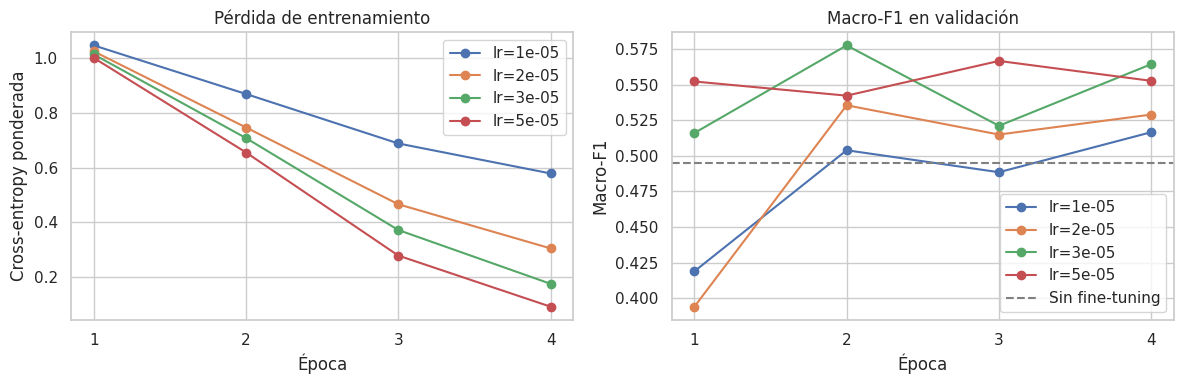

Learning rate elegido: 3e-05


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lr in LRS:
    h = historias[("learning_rate", f"lr={lr:.0e}")]
    axes[0].plot(h["epoca"], h["loss_train"], marker="o", label=f"lr={lr:.0e}")
    axes[1].plot(h["epoca"], h["macro_f1"], marker="o", label=f"lr={lr:.0e}")
axes[0].set_title("Pérdida de entrenamiento"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("Cross-entropy ponderada")
axes[1].set_title("Macro-F1 en validación"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("Macro-F1")
axes[1].axhline(MEJOR_SIN_FT["macro_f1"], ls="--", c="gray", label="Sin fine-tuning")
for ax in axes:
    ax.set_xticks(range(1, EPOCAS_LR + 1)); ax.legend()
plt.tight_layout(); plt.show()

LR = tab_lr["macro_f1"].idxmax()
LR = float(tab_lr.loc[LR, "lr"])
print(f"Learning rate elegido: {LR:.0e}")

**Observaciones**

- Todos los learning rates superan al encoder congelado (0,495): el peor, 1e-5, llega a 0,517, y los mejores son 3e-5 (0,578) y 5e-5 (0,567). Ningún valor hace colapsar al modelo a la clase mayoritaria.
- Velocidad de convergencia: con 1e-5 el modelo aprende despacio (pérdida de 0,58 al final de la 4.ª época y el mejor Macro-F1 recién en la última época, así que probablemente le faltaban épocas). Con 5e-5 la pérdida de entrenamiento baja a 0,09 en 4 épocas, señal de que el modelo ya está memorizando el conjunto de entrenamiento.

- El Macro-F1 de validación oscila entre épocas (por ejemplo, 3e-5: 0,516 → 0,578 → 0,521 → 0,564). Esas oscilaciones de ±3–5 puntos son del mismo orden que las diferencias entre 3e-5 y 5e-5, así que la elección entre ambos no es concluyente. Sí es claro que 1e-5 y 2e-5 son peores en 4 épocas.
- Se elige **3e-5**, dentro del rango recomendado para BERT.

#### 3.4.2. Cantidad de épocas

Con el learning rate elegido se entrena durante 8 épocas y se registra en cada una la pérdida de entrenamiento y el Macro-F1 (y F1 por clase) en validación. Así se ve a partir de qué época el modelo empieza a sobreajustar.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=3e-05 max_len=128 seed=42 | época 1/8 | loss=1.0337 | Macro-F1 val=0.513
  lr=3e-05 max_len=128 seed=42 | época 2/8 | loss=0.7551 | Macro-F1 val=0.556
  lr=3e-05 max_len=128 seed=42 | época 3/8 | loss=0.4034 | Macro-F1 val=0.555
  lr=3e-05 max_len=128 seed=42 | época 4/8 | loss=0.1643 | Macro-F1 val=0.551
  lr=3e-05 max_len=128 seed=42 | época 5/8 | loss=0.0664 | Macro-F1 val=0.543
  lr=3e-05 max_len=128 seed=42 | época 6/8 | loss=0.0179 | Macro-F1 val=0.579
  lr=3e-05 max_len=128 seed=42 | época 7/8 | loss=0.0068 | Macro-F1 val=0.552
  lr=3e-05 max_len=128 seed=42 | época 8/8 | loss=0.0023 | Macro-F1 val=0.554


,loss_train,macro_f1,accuracy,f1_favor,f1_against,f1_neutral
epoca,,,,,,
1,1.034,0.513,0.569,0.670,0.504,0.365
2,0.755,0.556,0.661,0.767,0.546,0.353
3,0.403,0.555,0.603,0.692,0.561,0.410
4,0.164,0.551,0.642,0.762,0.537,0.354
5,0.066,0.543,0.663,0.778,0.530,0.321
6,0.018,0.579,0.688,0.797,0.538,0.403
7,0.007,0.552,0.690,0.807,0.541,0.309
8,0.002,0.554,0.688,0.803,0.536,0.323


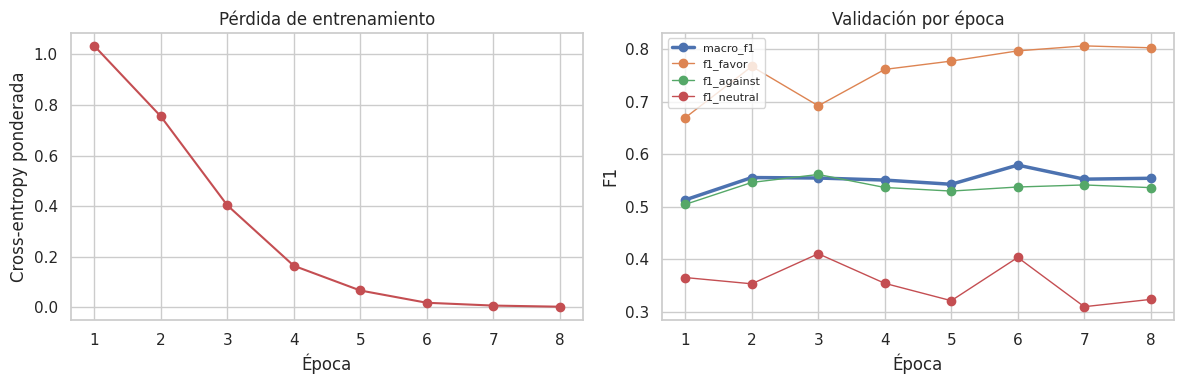

Mejor época: 6 → se entrenará con 6 épocas (conservando igualmente el mejor checkpoint por validación)


In [13]:
EPOCAS_MAX = 8
res_ep = correr("epocas", f"lr={LR:.0e} | {EPOCAS_MAX} épocas", lr=LR, epocas=EPOCAS_MAX, max_len=MAX_LEN_BASE)
h = historias[("epocas", f"lr={LR:.0e} | {EPOCAS_MAX} épocas")]
display(h.set_index("epoca").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h["epoca"], h["loss_train"], marker="o", c="C3")
axes[0].set_title("Pérdida de entrenamiento"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("Cross-entropy ponderada")
for col in ["macro_f1"] + [f"f1_{c}" for c in CLASES]:
    axes[1].plot(h["epoca"], h[col], marker="o", lw=2.5 if col == "macro_f1" else 1, label=col)
axes[1].set_title("Validación por época"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("F1")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(range(1, EPOCAS_MAX + 1))
plt.tight_layout(); plt.show()

EPOCAS = int(res_ep["mejor_epoca"])
print(f"Mejor época: {EPOCAS} → se entrenará con {EPOCAS} épocas "
      f"(conservando igualmente el mejor checkpoint por validación)")

**Observaciones**

- La pérdida de entrenamiento cae a casi 0 (1,03 → 0,002 en 8 épocas). El modelo memoriza completamente las ≈2.000 frases de entrenamiento (110 M de parámetros).
- El Macro-F1 de validación, en cambio, se estanca a partir de la época 2 (0,556) y oscila entre 0,543 y 0,579 hasta la época 8, sin una caída clara. Contra lo esperado, memorizar el entrenamiento no deteriora mucho la validación, pero tampoco la mejora.
- El máximo en la época 6 (0,579) es probablemente ruido, ya que está 2–3 puntos por encima de las épocas vecinas (0,543 y 0,552). Además, la misma configuración (3e-5, `max_len=128`) entrenada con 4 épocas había dado 0,578 en la época 2, y con 8 épocas da 0,556 en esa misma época. Es decir, solo cambiar la duración del *schedule* mueve el resultado ≈2 puntos.
- Por clase: *favor* mejora sostenidamente con más épocas (0,67 → 0,80), mientras que *neutral* oscila entre 0,31 y 0,41 sin tendencia (es la clase más inestable).

- Se eligen 6 épocas, pero como se conserva el mejor checkpoint según validación, en la práctica la cantidad de épocas actúa como un máximo. Cualquier valor entre 2 y 8 hubiera dado resultados similares.

#### 3.4.3. Longitud máxima de secuencia

Comparamos el desempeño y el costo (tiempo y VRAM) con distintas longitudes máximas. Con *padding* dinámico, cada batch se rellena solo hasta su entrada más larga, así que el ahorro de una longitud menor viene únicamente de truncar las entradas largas.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=3e-05 max_len=64 seed=42 | época 1/6 | loss=1.0340 | Macro-F1 val=0.479
  lr=3e-05 max_len=64 seed=42 | época 2/6 | loss=0.7504 | Macro-F1 val=0.568
  lr=3e-05 max_len=64 seed=42 | época 3/6 | loss=0.3679 | Macro-F1 val=0.498
  lr=3e-05 max_len=64 seed=42 | época 4/6 | loss=0.1699 | Macro-F1 val=0.538
  lr=3e-05 max_len=64 seed=42 | época 5/6 | loss=0.0589 | Macro-F1 val=0.518
  lr=3e-05 max_len=64 seed=42 | época 6/6 | loss=0.0151 | Macro-F1 val=0.523


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=3e-05 max_len=128 seed=42 | época 1/6 | loss=1.0248 | Macro-F1 val=0.519
  lr=3e-05 max_len=128 seed=42 | época 2/6 | loss=0.7322 | Macro-F1 val=0.555
  lr=3e-05 max_len=128 seed=42 | época 3/6 | loss=0.3774 | Macro-F1 val=0.560
  lr=3e-05 max_len=128 seed=42 | época 4/6 | loss=0.1548 | Macro-F1 val=0.565
  lr=3e-05 max_len=128 seed=42 | época 5/6 | loss=0.0552 | Macro-F1 val=0.558
  lr=3e-05 max_len=128 seed=42 | época 6/6 | loss=0.0185 | Macro-F1 val=0.553


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=3e-05 max_len=256 seed=42 | época 1/6 | loss=1.0203 | Macro-F1 val=0.510
  lr=3e-05 max_len=256 seed=42 | época 2/6 | loss=0.7452 | Macro-F1 val=0.547
  lr=3e-05 max_len=256 seed=42 | época 3/6 | loss=0.3841 | Macro-F1 val=0.556
  lr=3e-05 max_len=256 seed=42 | época 4/6 | loss=0.1680 | Macro-F1 val=0.531
  lr=3e-05 max_len=256 seed=42 | época 5/6 | loss=0.0569 | Macro-F1 val=0.536
  lr=3e-05 max_len=256 seed=42 | época 6/6 | loss=0.0241 | Macro-F1 val=0.544


,max_len,%_truncado,mejor_epoca,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_por_epoca_s,vram_pico_GB
experimento,,,,,,,,,,,
max_len=64,64,57.474,2,0.568,0.697,0.802,0.567,0.333,72.220,12.037,2.465
max_len=128,128,15.930,4,0.565,0.644,0.758,0.530,0.406,101.459,16.910,2.901
max_len=256,256,0.000,3,0.556,0.613,0.718,0.557,0.393,122.660,20.443,3.546


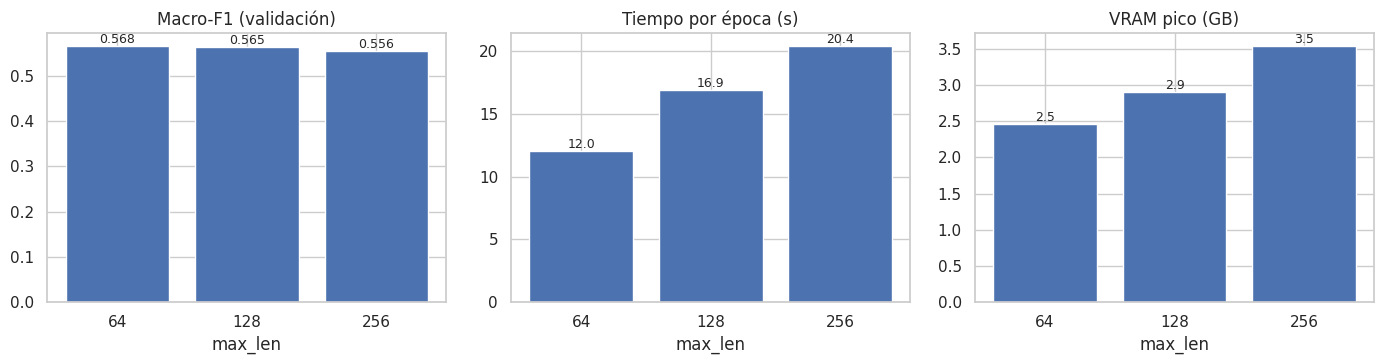

Longitud máxima elegida: 64


In [14]:
for L in LONGITUDES:
    correr("max_len", f"max_len={L}", lr=LR, epocas=EPOCAS, max_len=L)

tab_len = pd.DataFrame([c for c in corridas if c["grupo"] == "max_len"]).set_index("experimento")
tab_len["%_truncado"] = [(largos["propuesta + comentario"] > L).mean() * 100 for L in tab_len["max_len"]]
display(tab_len[["max_len", "%_truncado", "mejor_epoca"] + COLS_METRICAS +
                ["t_train_s", "t_por_epoca_s", "vram_pico_GB"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, titulo in zip(axes, ["macro_f1", "t_por_epoca_s", "vram_pico_GB"],
                           ["Macro-F1 (validación)", "Tiempo por época (s)", "VRAM pico (GB)"]):
    ax.bar(tab_len["max_len"].astype(str), tab_len[col], color="C0")
    ax.set_title(titulo); ax.set_xlabel("max_len")
    for i, v in enumerate(tab_len[col]):
        ax.text(i, v, f"{v:.3f}" if col == "macro_f1" else f"{v:.1f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

MAX_LEN = int(tab_len.loc[tab_len["macro_f1"].idxmax(), "max_len"])
print(f"Longitud máxima elegida: {MAX_LEN}")

**Observaciones**

- **Desempeño:** las tres longitudes quedan dentro de 1,2 puntos (64: 0,568 · 128: 0,565 · 256: 0,556). La diferencia está dentro del ruido.
- **Costo:** pasar de 128 a 64 tokens reduce el tiempo por época un 29% (16,9 → 12,0 s) y la VRAM de 2,9 a 2,5 GB. 256 tokens cuesta un 21% más de tiempo que 128 (y 3,5 GB) sin mejorar nada. Como el *padding* es dinámico, el ahorro proviene de las entradas que se truncan.
- Por qué 64 tokens no empeora: aunque trunca el 57,5% de las entradas, en un comentario la postura suele expresarse al principio (*"estoy de acuerdo"*, *"no tiene sentido"*...). Lo que se pierde es sobre todo la argumentación posterior.

- El criterio automático (mejor Macro-F1 en alguna época) eligió 64, pero ese 0,568 es un pico aislado en la época 2: en las demás épocas `max_len=64` da 0,479–0,538 (0,523 en la última), mientras que `max_len=128` es más estable (0,555–0,565 desde la época 2, 0,553 en la última). Además, con 64 el F1 de *neutral* en validación es el más bajo (0,333 contra 0,406). Con un criterio más robusto (Macro-F1 de la última época o promedio de las épocas 2–6), la elección habría sido 128. La configuración final se mantiene con 64 tal como la eligió el protocolo definido antes de mirar test, pero esta decisión es frágil.

### 3.5. Resumen de los experimentos en validación

Configuración final de fine-tuning: {'lr': 3e-05, 'epocas': 6, 'max_len': 64}


mejor_epoca  macro_f1  accuracy  f1_favor  \
grupo         experimento                                                      
learning_rate lr=1e-05                       4     0.517     0.569     0.665   
              lr=2e-05                       2     0.536     0.637     0.748   
              lr=3e-05                       2     0.578     0.692     0.794   
              lr=5e-05                       3     0.567     0.632     0.730   
epocas        lr=3e-05 | 8 épocas            6     0.579     0.688     0.797   
max_len       max_len=64                     2     0.568     0.697     0.802   
              max_len=128                    4     0.565     0.644     0.758   
              max_len=256                    3     0.556     0.613     0.718   

                                   f1_against  f1_neutral  macro_f1_ultima  \
grupo         experimento                                                    
learning_rate lr=1e-05                  0.512       0.373            0.517   
              lr=2e-05                  0.509       0.350            0.529   
              lr=3e-05                  0.547       0.391            0.564   
              lr=5e-05                  0.585       0.385            0.553   
epocas        lr=3e-05 | 8 épocas       0.538       0.403            0.554   
max_len       max_len=64                0.567       0.333            0.523   
              max_len=128               0.530       0.406            0.553   
              max_len=256               0.557       0.393            0.544   

                                   t_train_s  vram_pico_GB  
grupo         experimento                                   
learning_rate lr=1e-05                71.394         2.878  
              lr=2e-05                67.585         2.895  
              lr=3e-05                67.574         2.898  
              lr=5e-05                67.557         2.892  
epocas        lr=3e-05 | 8 épocas    135.003         2.898  
max_len       max_len=64              72.220         2.465  
              max_len=128            101.459         2.901  
              max_len=256            122.660         3.546

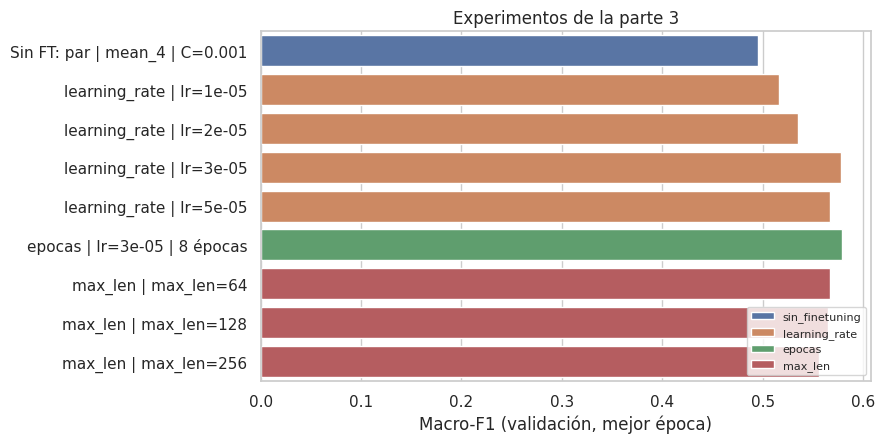

In [15]:
CONFIG_FINAL = {"lr": LR, "epocas": EPOCAS, "max_len": MAX_LEN}
print("Configuración final de fine-tuning:", CONFIG_FINAL)

tab_ft = pd.DataFrame(corridas)
display(tab_ft.set_index(["grupo", "experimento"])[["mejor_epoca"] + COLS_METRICAS +
                                                    ["macro_f1_ultima", "t_train_s", "vram_pico_GB"]].round(3))

# Gráfico resumen: mejor sin fine-tuning y todas las corridas de fine-tuning
resumen_val = pd.concat([
    pd.DataFrame([{"experimento": f"Sin FT: {MEJOR_SIN_FT['experimento']}", "grupo": "sin_finetuning",
                   "macro_f1": MEJOR_SIN_FT["macro_f1"]}]),
    tab_ft.assign(experimento=tab_ft["grupo"] + " | " + tab_ft["experimento"])[["experimento", "grupo", "macro_f1"]],
])
fig, ax = plt.subplots(figsize=(9, 0.4 * len(resumen_val) + 1))
sns.barplot(data=resumen_val, y="experimento", x="macro_f1", hue="grupo", dodge=False, ax=ax)
ax.set_xlabel("Macro-F1 (validación, mejor época)"); ax.set_ylabel("")
ax.set_title("Experimentos de la parte 3"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 3.6. Evaluación final en test

Recién ahora se usa el conjunto de test, una única vez, para:
1. **BETO sin fine-tuning:** la mejor configuración de (entrada, pooling y `C`), con la Regresión Logística entrenada en train.

2. **BETO con fine-tuning:** la configuración final (`CONFIG_FINAL`), entrenada en train con el mejor checkpoint elegido por validación.

Variabilidad entre semillas: el fine-tuning con pocos datos es sensible a la inicialización de la cabeza de clasificación y al orden de los batches. Para no reportar un resultado afortunado (o desafortunado), la configuración final se entrena con 3 semillas y se reporta la media y el desvío en validación y en test.

A diferencia de la parte 2, no se reentrena con train + validación, porque la validación se usa para elegir el mejor checkpoint.

In [16]:
res_test = []
preds_test = {}

# --- 1. BETO sin fine-tuning ---
ent, pool, C = MEJOR_SIN_FT["entrada"], MEJOR_SIN_FT["pooling"], MEJOR_SIN_FT["C"]
clf_sin_ft = clf_embeddings(C)
t0 = time.perf_counter(); clf_sin_ft.fit(EMB[(ent, "train")][pool], y_train); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); y_pred = clf_sin_ft.predict(EMB[(ent, "test")][pool]); t_pred = time.perf_counter() - t0
t_inf = T_EMB[(ent, "test")] + t_pred   # extraer embeddings + clasificar
NOMBRE_SIN_FT = f"BETO sin fine-tuning ({ent} | {pool} | C={C}) + LogReg"
preds_test[NOMBRE_SIN_FT] = y_pred
res_test.append({"modelo": NOMBRE_SIN_FT, **metricas(y_test, y_pred), "seed": SEED,
                 "t_train_s": T_EMB[(ent, "train")] + t_fit,   # embeddings de train + ajuste de la LogReg
                 "t_inf_test_s": t_inf, "t_inf_por_1000_s": t_inf / len(y_test) * 1000,
                 "vram_pico_GB": VRAM_EMB_GB, "tamaño_modelo_MB": TAMAÑO_BETO_MB})
print(NOMBRE_SIN_FT, f"→ Macro-F1 test = {res_test[-1]['macro_f1']:.3f}")

BETO sin fine-tuning (par | mean_4 | C=0.001) + LogReg → Macro-F1 test = 0.458


In [17]:
# --- 2. BETO con fine-tuning (3 semillas) ---
SEEDS_FINAL = [42, 43, 44]
finales_val = []

for seed in SEEDS_FINAL:
    resumen, historia, modelo = fine_tune(**CONFIG_FINAL, seed=seed, devolver_modelo=True)
    finales_val.append(resumen)

    # Calentamiento y luego inferencia cronometrada sobre test
    predecir(modelo, test_df.head(64), MAX_LEN)
    sincronizar(); t0 = time.perf_counter()
    y_pred = predecir(modelo, test_df, MAX_LEN)
    sincronizar(); t_inf = time.perf_counter() - t0

    nombre = f"BETO fine-tuning (seed={seed})"
    preds_test[nombre] = y_pred
    res_test.append({"modelo": nombre, **metricas(y_test, y_pred), "seed": seed,
                     "t_train_s": resumen["t_train_s"], "t_inf_test_s": t_inf,
                     "t_inf_por_1000_s": t_inf / len(y_test) * 1000,
                     "vram_pico_GB": resumen["vram_pico_GB"], "tamaño_modelo_MB": tamaño_modelo_mb(modelo)})
    print(nombre, f"→ Macro-F1 val = {resumen['macro_f1']:.3f} (época {resumen['mejor_epoca']}) | "
                  f"Macro-F1 test = {res_test[-1]['macro_f1']:.3f}")
    del modelo
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

finales_val = pd.DataFrame(finales_val)
print(f"\nMacro-F1 en validación (3 semillas): {finales_val['macro_f1'].mean():.3f} ± {finales_val['macro_f1'].std():.3f}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=3e-05 max_len=64 seed=42 | época 1/6 | loss=1.0340 | Macro-F1 val=0.479
  lr=3e-05 max_len=64 seed=42 | época 2/6 | loss=0.7504 | Macro-F1 val=0.568
  lr=3e-05 max_len=64 seed=42 | época 3/6 | loss=0.3679 | Macro-F1 val=0.498
  lr=3e-05 max_len=64 seed=42 | época 4/6 | loss=0.1699 | Macro-F1 val=0.538
  lr=3e-05 max_len=64 seed=42 | época 5/6 | loss=0.0589 | Macro-F1 val=0.518
  lr=3e-05 max_len=64 seed=42 | época 6/6 | loss=0.0151 | Macro-F1 val=0.523
BETO fine-tuning (seed=42) → Macro-F1 val = 0.568 (época 2) | Macro-F1 test = 0.482


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=3e-05 max_len=64 seed=43 | época 1/6 | loss=1.0259 | Macro-F1 val=0.474
  lr=3e-05 max_len=64 seed=43 | época 2/6 | loss=0.7533 | Macro-F1 val=0.519
  lr=3e-05 max_len=64 seed=43 | época 3/6 | loss=0.3899 | Macro-F1 val=0.521
  lr=3e-05 max_len=64 seed=43 | época 4/6 | loss=0.1437 | Macro-F1 val=0.529
  lr=3e-05 max_len=64 seed=43 | época 5/6 | loss=0.0602 | Macro-F1 val=0.531
  lr=3e-05 max_len=64 seed=43 | época 6/6 | loss=0.0228 | Macro-F1 val=0.545
BETO fine-tuning (seed=43) → Macro-F1 val = 0.545 (época 6) | Macro-F1 test = 0.489


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  lr=3e-05 max_len=64 seed=44 | época 1/6 | loss=1.0295 | Macro-F1 val=0.520
  lr=3e-05 max_len=64 seed=44 | época 2/6 | loss=0.7415 | Macro-F1 val=0.475
  lr=3e-05 max_len=64 seed=44 | época 3/6 | loss=0.3919 | Macro-F1 val=0.543
  lr=3e-05 max_len=64 seed=44 | época 4/6 | loss=0.1503 | Macro-F1 val=0.574
  lr=3e-05 max_len=64 seed=44 | época 5/6 | loss=0.0738 | Macro-F1 val=0.564
  lr=3e-05 max_len=64 seed=44 | época 6/6 | loss=0.0264 | Macro-F1 val=0.579
BETO fine-tuning (seed=44) → Macro-F1 val = 0.579 (época 6) | Macro-F1 test = 0.514

Macro-F1 en validación (3 semillas): 0.564 ± 0.017


In [18]:
test_tabla = pd.DataFrame(res_test).set_index("modelo")
ft = test_tabla[test_tabla.index.str.startswith("BETO fine-tuning")]
fila_media = ft.mean(numeric_only=True)
fila_std = ft.std(numeric_only=True)
test_tabla.loc["BETO fine-tuning (media de 3 semillas)"] = fila_media
test_tabla.loc["BETO fine-tuning (desvío entre semillas)"] = fila_std
test_tabla.loc[["BETO fine-tuning (media de 3 semillas)", "BETO fine-tuning (desvío entre semillas)"], "seed"] = np.nan

display(test_tabla.drop(columns="seed").round(3))
print(f"Macro-F1 test con fine-tuning: {fila_media['macro_f1']:.3f} ± {fila_std['macro_f1']:.3f}")

,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_inf_test_s,t_inf_por_1000_s,vram_pico_GB,tamaño_modelo_MB
modelo,,,,,,,,,,
BETO sin fine-tuning (par | mean_4 | C=0.001) + LogReg,0.458,0.502,0.604,0.459,0.311,7.604,1.463,3.501,2.050,439.404
BETO fine-tuning (seed=42),0.482,0.627,0.744,0.500,0.202,72.573,0.467,1.117,2.465,439.413
BETO fine-tuning (seed=43),0.489,0.589,0.720,0.440,0.308,72.082,0.535,1.279,2.444,439.413
BETO fine-tuning (seed=44),0.514,0.617,0.730,0.452,0.361,72.523,0.472,1.130,2.444,439.413
BETO fine-tuning (media de 3 semillas),0.495,0.611,0.731,0.464,0.290,72.393,0.491,1.175,2.451,439.413
BETO fine-tuning (desvío entre semillas),0.017,0.020,0.012,0.032,0.081,0.270,0.038,0.090,0.012,0.000


Macro-F1 test con fine-tuning: 0.495 ± 0.017


**Observaciones**

Resumen en test, junto con el modelo final de la parte 2:

| Modelo | Macro-F1 | Accuracy | F1 *favor* | F1 *against* | F1 *neutral* |
|---|---|---|---|---|---|
| Parte 2: n-gramas de caracteres + LogReg (train+val) | 0,435 | 0,529 | 0,667 | 0,346 | 0,292 |
| BETO sin fine-tuning + LogReg | 0,458 | 0,502 | 0,604 | 0,459 | 0,311 |
| BETO con fine-tuning (3 semillas) | **0,495 ± 0,017** | **0,611** | **0,731** | **0,464** | 0,290 ± 0,081 |

- **El fine-tuning es el mejor enfoque hasta ahora:** +3,7 puntos de Macro-F1 sobre el encoder congelado y +6 puntos sobre el modelo clásico. El encoder congelado queda solo 2,3 puntos por encima de la parte 2.

- **La mejora no viene de *neutral*:** el fine-tuning mejora *favor* (+6,4 puntos sobre la parte 2) y sobre todo *against* (+11,8 puntos), pero el F1 de *neutral* (0,29) es igual al de la parte 2 y además varía mucho entre semillas (0,20 / 0,31 / 0,36).
- **Caída de validación a test:** el fine-tuning pasa de 0,564 en validación (media de 3 semillas) a 0,495 en test (−6,9 puntos). El encoder congelado cae 3,7 puntos (0,495 → 0,458) y la parte 2 cae 5,8 puntos (0,493 → 0,435). Hay dos causas. Primero, el sesgo de selección, ya que el resultado de validación del fine-tuning es el máximo sobre épocas y configuraciones, con curvas muy ruidosas, y con el *early stopping* el checkpoint también se elige en validación. Segundo, el test parece algo más difícil, ya que todos los enfoques caen. La caída mayor del fine-tuning indica que su puntaje de validación es el más inflado.
- **Desvío entre semillas:** ±0,017 de Macro-F1, tanto en validación como en test. Es del mismo orden que las diferencias entre learning rates (3e-5 vs. 5e-5), épocas y longitudes de 3.4, así que esas comparaciones no son concluyentes con una sola semilla.


- **Costos:**
  - **Entrenamiento:** el fine-tuning final toma ≈72 s (6 épocas, `max_len=64`) en una T4 con 2,5 GB de VRAM pico. Todos los experimentos de esta parte (≈13 corridas) suman ≈20 minutos de GPU. La parte 2 entrena en 3,7 s en CPU.
  - **Inferencia:** el fine-tuning procesa ≈1,2 s cada 1.000 comentarios en GPU, contra ≈0,6 s en CPU para el modelo clásico. En CPU, BETO sería uno o dos órdenes de magnitud más lento.
  - **Encoder congelado:** su inferencia (3,5 s cada 1.000 comentarios) es más lenta que la del modelo con fine-tuning porque se extrajo con `max_len=256` y guardando todas las capas ocultas, no por el enfoque en sí.
  - **Tamaño:** BETO ocupa ≈440 MB en fp32, contra ≈1,3 MB del modelo clásico.

### 3.7. Análisis de resultados

#### 3.7.1. Matrices de confusión y F1 por clase

Para el modelo con fine-tuning se muestra la semilla con Macro-F1 de validación más cercano a la mediana (la selección no usa el test).

Semilla representativa: 42


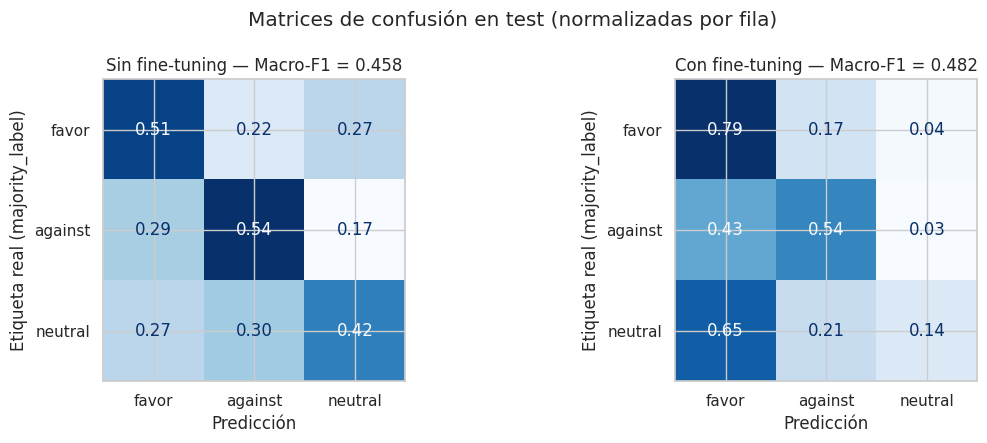

=== BETO con fine-tuning ===
              precision    recall  f1-score   support

       favor      0.706     0.786     0.744       257
     against      0.468     0.537     0.500        95
     neutral      0.391     0.136     0.202        66

    accuracy                          0.627       418
   macro avg      0.522     0.486     0.482       418
weighted avg      0.602     0.627     0.603       418



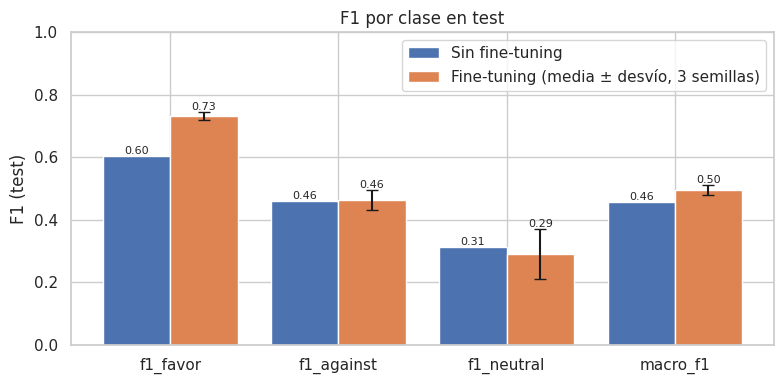

In [19]:
seed_rep = int(finales_val.iloc[(finales_val["macro_f1"] - finales_val["macro_f1"].median()).abs().argmin()]["seed"])
NOMBRE_FT = f"BETO fine-tuning (seed={seed_rep})"
print("Semilla representativa:", seed_rep)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (titulo, nombre) in zip(axes, [("Sin fine-tuning", NOMBRE_SIN_FT), ("Con fine-tuning", NOMBRE_FT)]):
    y_pred = preds_test[nombre]
    cm = confusion_matrix(y_test, y_pred, labels=CLASES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{titulo} — Macro-F1 = {f1_score(y_test, y_pred, average='macro'):.3f}")
    ax.set_xlabel("Predicción"); ax.set_ylabel("Etiqueta real (majority_label)")
plt.suptitle("Matrices de confusión en test (normalizadas por fila)"); plt.tight_layout(); plt.show()

print("=== BETO con fine-tuning ===")
print(classification_report(y_test, preds_test[NOMBRE_FT], labels=CLASES, digits=3))

cols_f1 = [f"f1_{c}" for c in CLASES] + ["macro_f1"]
x = np.arange(len(cols_f1))
fig, ax = plt.subplots(figsize=(8, 4))
barras_sin = ax.bar(x - 0.2, test_tabla.loc[NOMBRE_SIN_FT, cols_f1].to_numpy(dtype=float), 0.4,
                    label="Sin fine-tuning")
barras_ft = ax.bar(x + 0.2, fila_media[cols_f1].to_numpy(dtype=float), 0.4,
                   yerr=fila_std[cols_f1].to_numpy(dtype=float), capsize=4,
                   label="Fine-tuning (media ± desvío, 3 semillas)")
ax.bar_label(barras_sin, fmt="%.2f", fontsize=8)
ax.bar_label(barras_ft, fmt="%.2f", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(cols_f1)
ax.set_ylabel("F1 (test)"); ax.set_title("F1 por clase en test"); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.show()

**Observaciones**

- **El modelo con fine-tuning casi no predice *neutral*:** la semilla representativa (42) lo predice solo en 23 de 418 comentarios y recupera 9 de los 66 *neutral* (recall 0,14). El 65% de los *neutral* se clasifica como *favor*, la frontera más difusa entre anotadores (parte 1). También el 43% de los *against* se predice como *favor*.

- **Esta semilla es la peor en *neutral*:** su checkpoint es de la época 2, con un modelo todavía poco entrenado. Las semillas 43 y 44, con checkpoints de la época 6, predicen *neutral* 77 y 56 veces y recuperan 22 de 66 (F1 0,31 y 0,36). Aunque la cross-entropy esté ponderada por clase, cuánto predice el modelo *neutral* depende mucho de la semilla y de la época elegida.
- **El encoder congelado tiene el comportamiento opuesto:** predice *neutral* 114 veces (recupera 28 de 66) a costa de *favor* (solo el 51% de los *favor* bien clasificados). Su F1 de *neutral* termina siendo similar.
- El fine-tuning gana sobre todo en *favor* (recall 0,79) y en *against*: es mejor separando *favor* de *against*, pero no aprende a reconocer *neutral*.

#### 3.7.2. Desempeño según el acuerdo entre anotadores

Si el modelo falla sobre todo en los comentarios donde los anotadores tampoco coincidieron, parte del error se explica por la ambigüedad de las etiquetas.

In [20]:
filas = []
for nombre in [NOMBRE_SIN_FT, NOMBRE_FT]:
    for nivel in ["Total (3/3)", "Parcial (2/3)"]:
        m = (test_df["nivel_acuerdo"] == nivel).to_numpy()
        filas.append({"modelo": nombre, "nivel_acuerdo": nivel, "n": m.sum(),
                      "accuracy": accuracy_score(y_test[m], preds_test[nombre][m]),
                      "macro_f1": f1_score(y_test[m], preds_test[nombre][m], labels=CLASES,
                                           average="macro", zero_division=0)})
display(pd.DataFrame(filas).set_index(["modelo", "nivel_acuerdo"]).round(3))

n  \
modelo                                             nivel_acuerdo        
BETO sin fine-tuning (par | mean_4 | C=0.001) +... Total (3/3)    216   
                                                   Parcial (2/3)  202   
BETO fine-tuning (seed=42)                         Total (3/3)    216   
                                                   Parcial (2/3)  202   

                                                                  accuracy  \
modelo                                             nivel_acuerdo             
BETO sin fine-tuning (par | mean_4 | C=0.001) +... Total (3/3)       0.588   
                                                   Parcial (2/3)     0.411   
BETO fine-tuning (seed=42)                         Total (3/3)       0.759   
                                                   Parcial (2/3)     0.485   

                                                                  macro_f1  
modelo                                             nivel_acuerdo            
BETO sin fine-tuning (par | mean_4 | C=0.001) +... Total (3/3)       0.481  
                                                   Parcial (2/3)     0.406  
BETO fine-tuning (seed=42)                         Total (3/3)       0.549  
                                                   Parcial (2/3)     0.412

**Observaciones**

| Acuerdo | n | Parte 2 (Macro-F1 / acc.) | BETO sin FT | BETO con FT (seed 42) |
|---|---|---|---|---|
| Total (3/3) | 216 | 0,468 / 0,639 | 0,481 / 0,588 | **0,549 / 0,759** |
| Parcial (2/3) | 202 | 0,377 / 0,411 | 0,406 / 0,411 | 0,412 / 0,485 |

- La mejora del fine-tuning se concentra en los comentarios con acuerdo total: +8 puntos de Macro-F1 y +12 de accuracy respecto de la parte 2.
- En los comentarios con acuerdo parcial, los tres enfoques quedan cerca (Macro-F1 0,38–0,41). Esos casos son ambiguos también para los humanos, y en ellos un modelo más potente casi no gana.

#### 3.7.3. Ejemplos de errores del modelo con fine-tuning

In [21]:
errores = test_df.assign(pred=preds_test[NOMBRE_FT])[lambda d: d["pred"] != d["label"]]
print(f"Errores en test: {len(errores)} de {len(test_df)}\n")
for (real, pred), g in errores.groupby(["label", "pred"]):
    if len(g) < 5:
        continue
    print(f"=== Real: {real} | Predicho: {pred} ({len(g)} casos) ===")
    for _, fila in g.sample(min(2, len(g)), random_state=SEED).iterrows():
        print(f"• [{fila['target'][:60]}] {fila['comment'][:250]}")
        print(f"  Anotaciones: {fila[cols_anotadores].tolist()}\n")

Errores en test: 156 de 418

=== Real: against | Predicho: favor (41 casos) ===
• [Parar motores EMT cuando el conductor descansa?] Los buses se quedan encendidos por temas mecanicos. y para que al subir al autobus no tengas que pasar frio o calor  dependiendo de la epoca del año
  Anotaciones: ['against', 'against', 'favor']

• [Metro por las noches (Fines de semana)] Conlleva un sobrecoste que no debe ser asumido por un presupuesto municipal en mi humilde opinión.
  Anotaciones: ['against', 'favor', 'against']

=== Real: favor | Predicho: against (44 casos) ===
• [Reprobación de Esperanza Aguirre como concejala del Ayuntami] Por supuestísimo que esta señorona, no puede representar a nadie. Ni a ella misma, corre el riesgo de que se robe y lo done al PP. (bueno un parte claro).
Hay un refrán muy español que dice: "A todo cerdo/a, le llega su SanMartín".
  Anotaciones: ['favor', 'favor', 'against']

• [No a los ruidos.  Reducir el número de decibelios permitido.] LA causa común a mucho

**Observaciones**

- Los errores típicos son los mismos de la parte 2, incluso varios de los mismos comentarios:
  - El de los buses encendidos (*against*, se predice *favor*): para entenderlo hay que relacionarlo con la propuesta.
  - La crítica dura a la concejala (*favor* de su reprobación, se predice *against*).
  - Preguntas o aclaraciones de contexto (*neutral*).
- Recibir la propuesta como segundo segmento no fue suficiente para que el modelo aprenda la relación entre propuesta y comentario con ≈2.000 ejemplos: sigue respondiendo en buena medida al tono del comentario (palabras negativas → *against*).

- Varios de los errores tienen anotaciones divididas (2 a 1), donde la etiqueta de referencia es discutible. Pero también hay errores con acuerdo total, como comentarios *neutral* informativos (la historia del metro) que el modelo clasifica como *favor*.

#### 3.7.4. Comparación con la parte 2

Se comparan desempeño y costo de los enfoques evaluados hasta ahora, a partir de `resultados_parte2_test.csv` (generado por la parte 2) y de los resultados de test de esta parte. La comparación completa entre enfoques (incluidos los LLMs) se hace en la parte 5.

*La celda es autónoma:* si no están en memoria los resultados de esta parte, los lee de `resultados_parte3_test.csv`. Se puede ejecutar sola, sin GPU y sin volver a correr el notebook.

,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_inf_por_1000_s,tamaño_modelo_MB,hardware,macro_f1_desvio
P2: baseline (TF-IDF + LogReg),0.309,0.629,0.772,0.095,0.059,0.886,0.079,0.570,CPU,0.000
P2: n-gramas de caracteres + LogReg,0.435,0.529,0.667,0.346,0.292,3.616,0.654,1.341,CPU,0.000
P3: BETO congelado + LogReg,0.458,0.502,0.604,0.459,0.311,7.604,3.501,439.404,GPU (T4),0.000
P3: BETO fine-tuning (3 semillas),0.495,0.611,0.731,0.464,0.290,72.393,1.175,439.413,GPU (T4),0.017


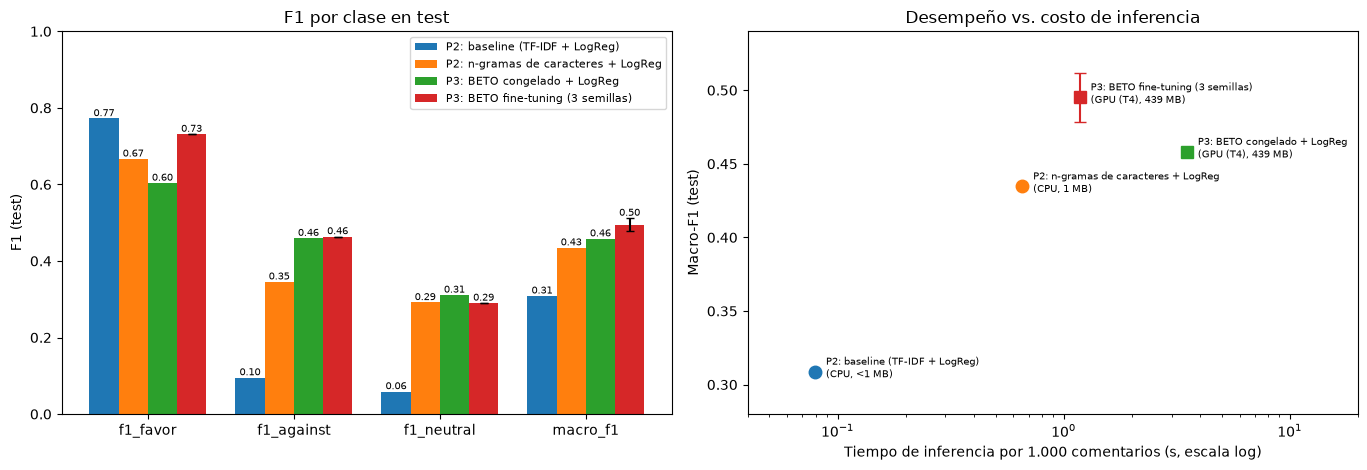

Nota: los tiempos de la parte 2 se midieron en CPU (2 núcleos de Colab) y los de la parte 3 en una GPU T4.

In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Parte 3: se usa la tabla en memoria si existe; si no (por ejemplo, al ejecutar solo esta celda
# en un entorno nuevo), se lee el CSV guardado en 3.8. No requiere GPU.
if "test_tabla" in globals():
    p3 = test_tabla.copy()
else:
    p3 = pd.read_csv("resultados_parte3_test.csv", index_col=0)

RUTA_P2 = "resultados_parte2_test.csv"
if not os.path.exists(RUTA_P2):
    try:
        from google.colab import files
        print("No se encontró resultados_parte2_test.csv: subilo (lo genera la parte 2).")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Falta resultados_parte2_test.csv (lo genera la parte 2).")
p2 = pd.read_csv(RUTA_P2, index_col=0)
p2["t_inf_por_1000_s"] = p2["t_inf_por_1000_ms"] / 1000
p2["hardware"] = "CPU"
p3["hardware"] = "GPU (T4)"

COLS_COMP = ["macro_f1", "accuracy", "f1_favor", "f1_against", "f1_neutral",
             "t_train_s", "t_inf_por_1000_s", "tamaño_modelo_MB", "hardware"]
nombre_sin_ft = next(m for m in p3.index if m.startswith("BETO sin fine-tuning"))
comp = pd.concat([
    p2.loc[["Baseline (TF-IDF 1-gramas + LogReg)", "Elegido: LogReg C=1 (train+val)"], COLS_COMP],
    p3.loc[[nombre_sin_ft, "BETO fine-tuning (media de 3 semillas)"], COLS_COMP],
])
comp.index = ["P2: baseline (TF-IDF + LogReg)", "P2: n-gramas de caracteres + LogReg",
              "P3: BETO congelado + LogReg", "P3: BETO fine-tuning (3 semillas)"]
comp["macro_f1_desvio"] = [0, 0, 0, p3.loc["BETO fine-tuning (desvío entre semillas)", "macro_f1"]]
display(comp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# F1 por clase y Macro-F1
cols_f1 = ["f1_favor", "f1_against", "f1_neutral", "macro_f1"]
ancho = 0.2
for i, (nombre, fila) in enumerate(comp.iterrows()):
    pos = [j + (i - 1.5) * ancho for j in range(len(cols_f1))]
    err = [0, 0, 0, fila["macro_f1_desvio"]] if fila["macro_f1_desvio"] > 0 else None
    barras = axes[0].bar(pos, fila[cols_f1].astype(float), ancho, yerr=err, capsize=3, label=nombre)
    axes[0].bar_label(barras, fmt="%.2f", fontsize=7)
axes[0].set_xticks(range(len(cols_f1))); axes[0].set_xticklabels(cols_f1)
axes[0].set_ylim(0, 1); axes[0].set_ylabel("F1 (test)"); axes[0].set_title("F1 por clase en test")
axes[0].legend(fontsize=8, loc="upper right")

# Desempeño vs. costo de inferencia
for i, (nombre, fila) in enumerate(comp.iterrows()):
    axes[1].errorbar(fila["t_inf_por_1000_s"], fila["macro_f1"], yerr=fila["macro_f1_desvio"],
                     fmt="o" if fila["hardware"] == "CPU" else "s", ms=9, capsize=4, color=f"C{i}")
    axes[1].annotate(f"{nombre}\n({fila['hardware']}, {fila['tamaño_modelo_MB']:.0f} MB)"
                     if fila["tamaño_modelo_MB"] >= 1 else f"{nombre}\n({fila['hardware']}, <1 MB)",
                     (fila["t_inf_por_1000_s"], fila["macro_f1"]), textcoords="offset points",
                     xytext=(8, -4), fontsize=7.5)
axes[1].set_xscale("log"); axes[1].set_xlim(0.04, 20); axes[1].set_ylim(0.28, 0.54)
axes[1].set_xlabel("Tiempo de inferencia por 1.000 comentarios (s, escala log)")
axes[1].set_ylabel("Macro-F1 (test)"); axes[1].set_title("Desempeño vs. costo de inferencia")
plt.tight_layout(); plt.show()
print("Nota: los tiempos de la parte 2 se midieron en CPU (2 núcleos de Colab) y los de la parte 3 en una GPU T4.")

**Observaciones**

- **Desempeño:** cada paso agrega algo, pero con rendimientos decrecientes. El balanceo de clases y las features de la parte 2 llevan el Macro-F1 de 0,309 a 0,435. Usar BETO congelado agrega 2,3 puntos (0,458) y el fine-tuning 3,7 más (**0,495 ± 0,017**). El fine-tuning supera al mejor modelo clásico por ≈6 puntos, una diferencia mayor que el desvío entre semillas.
- **Por clase:** la ganancia de los encoders está en *against* (0,35 → 0,46) y, en el caso del fine-tuning, también en *favor* (0,67 → 0,73). En *neutral*, los tres modelos no triviales quedan prácticamente igual (0,29–0,31): ningún enfoque probado hasta ahora resuelve la clase más ambigua.
- **Costos:**
  - **Inferencia:** el modelo clásico predice 1.000 comentarios en ≈0,65 s en CPU. BETO con fine-tuning tarda ≈1,2 s en una GPU T4, y en CPU sería mucho más lento.
  - **Entrenamiento:** ≈3,6 s en CPU contra ≈72 s en GPU, sin contar ≈20 min de exploración de hiperparámetros.
  - **Tamaño:** ≈1,3 MB contra ≈440 MB.
- **Lectura del gráfico:** pasar del modelo clásico al fine-tuning implica, aproximadamente, +6 puntos de Macro-F1 a cambio de necesitar GPU y un modelo 300 veces más grande. El encoder congelado no es un buen punto intermedio: mejora poco, cuesta casi lo mismo que el fine-tuning en inferencia y también necesita el encoder completo.

### 3.8. Guardado de resultados

Se guardan los resultados para la comparación entre enfoques (parte 5):
- `resultados_parte3_val.csv`: experimentos sin fine-tuning y corridas de fine-tuning sobre validación.
- `resultados_parte3_epocas.csv`: métricas por época de cada corrida de fine-tuning.
- `resultados_parte3_test.csv`: métricas, tiempos, VRAM y tamaño en test.
- `predicciones_parte3_test.csv`: predicciones en test de cada modelo (para comparaciones por comentario entre enfoques).

In [23]:
pd.concat([pd.DataFrame([r for r in resultados if r["grupo"] == "sin_finetuning"]),
           pd.DataFrame(corridas),
           finales_val.assign(grupo="final_semillas", experimento=lambda d: "seed=" + d["seed"].astype(str))],
          ignore_index=True).to_csv("resultados_parte3_val.csv", index=False)

pd.concat([h.assign(grupo=g, experimento=e) for (g, e), h in historias.items()],
          ignore_index=True).to_csv("resultados_parte3_epocas.csv", index=False)

test_tabla.assign(**{f"config_{k}": v for k, v in CONFIG_FINAL.items()},
                  gpu=torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu"
                  ).to_csv("resultados_parte3_test.csv")

pd.DataFrame({"id": test_df["id"], "label": y_test,
              "pred_sin_finetuning": preds_test[NOMBRE_SIN_FT],
              **{f"pred_finetuning_seed{s}": preds_test[f"BETO fine-tuning (seed={s})"] for s in SEEDS_FINAL}}
             ).to_csv("predicciones_parte3_test.csv", index=False)
print("Archivos guardados.")

try:   # en Colab, descarga los archivos para no perderlos al cerrar el entorno
    from google.colab import files
    for f in ["resultados_parte3_val.csv", "resultados_parte3_epocas.csv",
              "resultados_parte3_test.csv", "predicciones_parte3_test.csv"]:
        files.download(f)
except ImportError:
    pass

Archivos guardados.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 3.9. Conclusiones de la parte 3

- **Sin fine-tuning:** los embeddings congelados de BETO + Regresión Logística obtienen un Macro-F1 en test de **0,458**, apenas 2,3 puntos por encima del modelo clásico de la parte 2 (0,435) y prácticamente igual en validación (0,495 vs. 0,493). Las representaciones genéricas de un encoder sin ajustar capturan más el tema y el estilo que la postura. El pooling y agregar la propuesta tienen efectos menores que el ruido.
- **Con fine-tuning:** el Macro-F1 en test es **0,495 ± 0,017** (3 semillas), +3,7 puntos respecto del encoder congelado y **+6 respecto de la parte 2**. La mejora viene de *favor* y sobre todo de *against* (F1 0,35 → 0,46) y de los comentarios con acuerdo total entre anotadores.
- **Decisiones de entrenamiento:**
  - El learning rate fue lo más influyente: 1e-5 es demasiado lento para 4 épocas, y 3e-5 y 5e-5 son los mejores, con diferencias dentro del ruido.
  - El modelo memoriza el entrenamiento en 4–5 épocas (pérdida ≈ 0), pero el Macro-F1 de validación se estanca desde la época 2.
  - La longitud máxima importa poco para el desempeño: 64 tokens dan un resultado similar a 128 y 256 con un 29% y un 41% menos de tiempo por época, respectivamente, aunque con 64 el modelo es más inestable en *neutral*.
- **Costos:** el fine-tuning requiere GPU (≈2,5–3,5 GB de VRAM según la longitud, ≈72 s de entrenamiento en una T4 para la configuración final y ≈20 min para toda la exploración), y el modelo ocupa ≈440 MB. La inferencia toma ≈1,2 s cada 1.000 comentarios en GPU, contra ≈0,6 s en CPU para el modelo clásico, que pesa ≈1,3 MB.
- **Limitaciones:**
  - *neutral* sigue siendo la clase más difícil (F1 = 0,29 ± 0,08, igual que la parte 2): el modelo la confunde mayormente con *favor*, y cuánto la predice depende de la semilla.
  - Con validación y test chicos (≈65 *neutral* en cada uno), la varianza entre semillas (± 0,017) y entre épocas (± 2–3 puntos) es comparable a las diferencias entre configuraciones. Por eso el puntaje de validación del fine-tuning está inflado (cae 6,9 puntos en test).
  - La elección de `max_len=64` se apoyó en un pico de una sola época.
  - Darle la propuesta como segundo segmento no alcanzó para que el modelo resuelva los comentarios cuya postura depende de la propuesta.